# Glass Type Identification

Forensic glass analysis: a fragment's chemistry — refractive index plus the percentage of sodium, magnesium, aluminium, silicon, potassium, calcium, barium and iron — depends on what the glass was made for. Identify the **glass type** (building or vehicle windows, containers, tableware, headlamps) from 9 measurements. The dataset's classes run 1, 2, 3, 5, 6, 7: **class 4 (vehicle windows, non-float processed) has no samples** in the data.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

raw = download('https://archive.ics.uci.edu/static/public/42/glass+identification.zip')
zf = zipfile.ZipFile(io.BytesIO(raw))
name = [n for n in zf.namelist() if n.endswith('.data')][0]
df = pd.read_csv(io.BytesIO(zf.read(name)), header=None)
print(df.shape)
print('Class counts (note: class 4 does not exist in this dataset):')
print(df.iloc[:, 10].value_counts().sort_index())
df.head(3)

(214, 11)
Class counts (note: class 4 does not exist in this dataset):
10
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


,0,1,2,3,4,5,6,7,8,9,10
0,1,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,2,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,3,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1


In [2]:
X = df.iloc[:, 1:10]; y = df.iloc[:, 10]  # column 0 is just an Id number
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print(f'Random Forest accuracy: {accuracy_score(yte, rf.predict(Xte)):.4f}')
print(f'Logistic Regression accuracy: {accuracy_score(yte, lr.predict(Xte)):.4f}')
print(classification_report(yte, rf.predict(Xte)))

Random Forest accuracy: 0.8333
Logistic Regression accuracy: 0.7037
              precision    recall  f1-score   support

           1       0.77      0.94      0.85        18
           2       0.88      0.74      0.80        19
           3       1.00      0.50      0.67         4
           5       0.67      0.67      0.67         3
           6       0.67      1.00      0.80         2
           7       1.00      1.00      1.00         8

    accuracy                           0.83        54
   macro avg       0.83      0.81      0.80        54
weighted avg       0.85      0.83      0.83        54



Mg    0.158811
Al    0.154815
RI    0.136147
Ca    0.126972
Na    0.114555
Si    0.095632
K     0.091618
Ba    0.077055
Fe    0.044395
dtype: float64


<Axes: title={'center': 'Which chemistry separates glass types?'}>

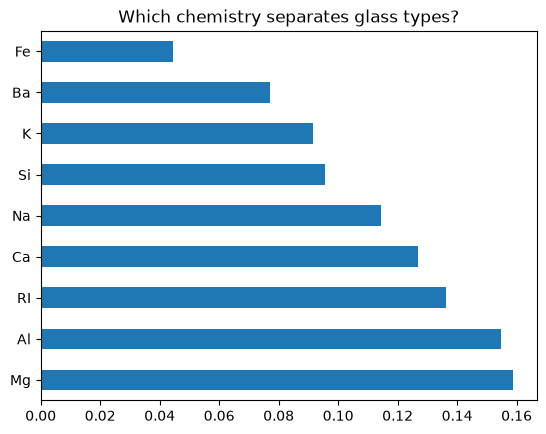

In [3]:
feat = ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']
imp = pd.Series(rf.feature_importances_, index=feat).sort_values(ascending=False)
print(imp)
imp.plot(kind='barh', title='Which chemistry separates glass types?')